# Retrieval-augmented generation: the basics

A language model answers from what it absorbed during training. That knowledge is frozen on the day training stopped, it is public, and it is approximate: ask for an exact figure from a document the model never saw and it will produce a confident sentence that may be wrong. **Retrieval-augmented generation (RAG)** is the standard fix. Keep the documents outside the model, find the few passages that matter for the question, and put only those in the prompt, so the model answers from evidence it can cite.

This notebook explains the idea and builds the smallest complete version of it, over a corpus you can check: the documents of this course. It needs no API key. The one step that calls a real model (section 6) runs only if you have an `ANTHROPIC_API_KEY`, and explains itself otherwise.

**What you will learn**

- Why a prompt alone, a fine-tuned model and a RAG system are three different answers to "how do I give the model my knowledge"
- The five steps of the pipeline: chunk, embed, retrieve, augment, generate, and what each one costs
- What an embedding is, why cosine similarity measures "about the same thing", and where keyword search beats neural embeddings and vice versa
- How to measure retrieval with hit rate and mean reciprocal rank, and why "not in the documents" questions belong in every test set
- The design choices and failure modes you will meet in any real RAG system, including the security one

## How to run this notebook

- **Locally (Jupyter or VS Code):** open it from the repository and run the cells top to bottom. The corpus is read from the repository itself.
- **Google Colab:** open it with the badge in the README, or upload it. The setup cell downloads the corpus from the course repository on GitHub.

Two optional extras, both detected automatically:

- `sentence-transformers` gives neural embeddings in section 3. Without it the notebook runs on keyword embeddings (TF-IDF) and says so; on Colab the setup cell installs it.
- An `ANTHROPIC_API_KEY` in a git-ignored `.env` at the repository root (or in the environment) lets section 6 generate real answers. Without it, section 6 shows the exact prompt that would be sent and skips the call. Never paste a key into a cell.

In [1]:
import os
import re
import sys
import textwrap
import urllib.parse
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, GREY, INK = "#2a78d6", "#9aa5b1", "#1b2430"

# The corpus: the course's own documents, so every answer can be checked by opening the file.
CORPUS_FILES = [
    "README.md", "CONTRIBUTING.md", "SECURITY.md", "presentations/README.md",
    "M3 - Natural Language Processing/README.md", "M4 - Generative AI/README.md",
    "M5 - Harness Engineering/README.md",
]
RAW = "https://raw.githubusercontent.com/maglionejm/fontys-tech-exercises/main/"


def find_repo_root(start: Path):
    for candidate in [start, *start.parents]:
        if (candidate / "README.md").exists() and (candidate / "M4 - Generative AI").is_dir():
            return candidate
    return None


ROOT = find_repo_root(Path.cwd().resolve())
documents = {}
for rel in CORPUS_FILES:
    if ROOT is not None:
        documents[rel] = (ROOT / rel).read_text(encoding="utf-8")
    else:                                            # Colab or a copy elsewhere: fetch from GitHub
        with urllib.request.urlopen(RAW + urllib.parse.quote(rel), timeout=60) as r:
            documents[rel] = r.read().decode("utf-8")
print("source:", "local repository" if ROOT is not None else "downloaded from GitHub")
for rel, text in documents.items():
    print(f"  {len(text.split()):>5} words  {rel}")

# Optional: neural embeddings. Installed on Colab when missing; elsewhere the notebook falls back to TF-IDF.
import logging
import warnings
warnings.filterwarnings("ignore")                                   # library start-up chatter is not part of the lesson
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_VERBOSITY", "error")
for noisy in ("torch.distributed.elastic.multiprocessing.redirects", "huggingface_hub", "transformers", "sentence_transformers"):
    logging.getLogger(noisy).setLevel(logging.ERROR)
try:
    from sentence_transformers import SentenceTransformer
    HAVE_DENSE = True
except ImportError:
    HAVE_DENSE = False
    if "google.colab" in sys.modules:
        import subprocess
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "sentence-transformers"])
        from sentence_transformers import SentenceTransformer
        HAVE_DENSE = True

# Optional: a real model for section 6. The key is read, never printed.
API_KEY = None
try:
    from dotenv import dotenv_values
    if ROOT is not None:
        API_KEY = dotenv_values(ROOT / ".env").get("ANTHROPIC_API_KEY") or None
except ImportError:
    pass
API_KEY = API_KEY or os.environ.get("ANTHROPIC_API_KEY") or None
if API_KEY is None and "google.colab" in sys.modules:
    try:
        from google.colab import userdata
        API_KEY = userdata.get("ANTHROPIC_API_KEY") or None
    except Exception:
        API_KEY = None
print("neural embeddings:", "available" if HAVE_DENSE else "not installed, using TF-IDF only")
print("real model for section 6:", "key found" if API_KEY else "no key, section 6 will show the prompt and skip the call")

source: local repository
   2393 words  README.md
    568 words  CONTRIBUTING.md
    225 words  SECURITY.md
    457 words  presentations/README.md
    559 words  M3 - Natural Language Processing/README.md
   1555 words  M4 - Generative AI/README.md
   1402 words  M5 - Harness Engineering/README.md


neural embeddings: available
real model for section 6: key found


## 1. The problem RAG solves

> **In plain words:** a language model takes a closed-book exam. It answers from memory, and its memory is whatever was in its training data, as of the day training stopped. RAG turns the exam into an **open-book exam**: before answering, the model is handed the right pages.

Three situations break the closed-book model:

1. **Recent facts.** Anything that happened after training is unknown to it.
2. **Private documents.** Your company's policies, your course's rules, your own notes were never in the training data.
3. **Exact figures.** Even for things it has seen, a model reconstructs; it does not look up. Ask for the precise number in a report and you get a plausible one.

In all three cases the model does not say "I do not know" by default. It produces fluent text. That is the failure called **hallucination**, and it is the main reason RAG exists.

There are three ways to give a model your knowledge:

| Approach | How | Good for | Costs and limits |
|---|---|---|---|
| **Fine-tuning** | Train the model further on your texts | Style, format, vocabulary, a stable domain | Expensive, slow to update, still frozen, poor at exact facts and citations |
| **Everything in the prompt** | Paste all documents before the question | Small, stable sets that fit the context window | Tokens cost money on every call; models get worse as the prompt fills with irrelevant text (Liu et al., 2023, "lost in the middle") |
| **RAG** | Store documents outside the model; retrieve the relevant passages per question; put only those in the prompt | Large or changing corpora, exact facts, answers with sources | Quality is capped by retrieval: hand the model the wrong page and it answers from the wrong page |

RAG was named and formalised by Lewis et al. (2020). The core idea is older than the name: search first, then write.

The pipeline has two phases. **Indexing** happens once, offline, when documents change. **Querying** happens on every question. The picture below is the whole architecture; every later section is one box.

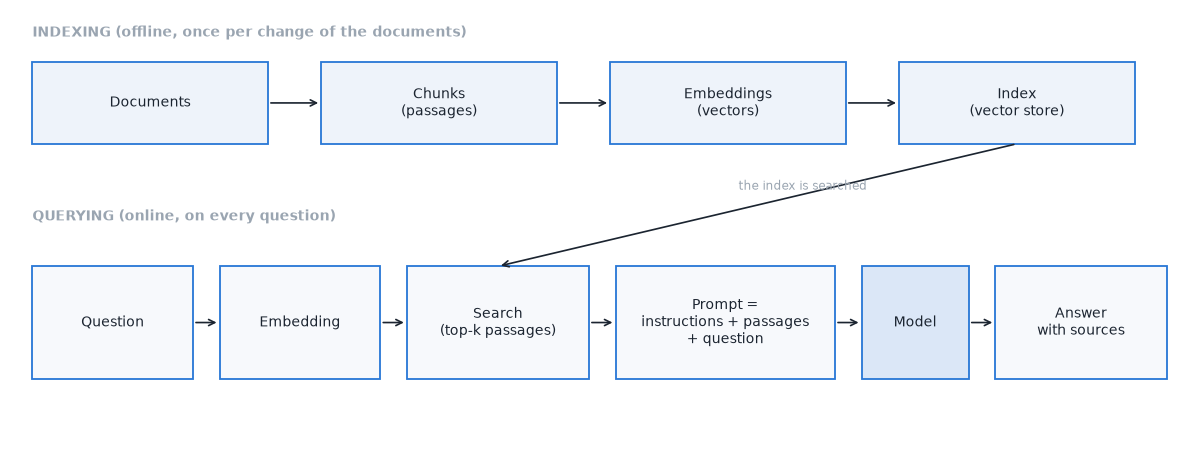

In [2]:
def box(ax, x, y, w, h, text, fill="#eef3fa", edge=BLUE):
    ax.add_patch(plt.Rectangle((x, y), w, h, facecolor=fill, edgecolor=edge, linewidth=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=9, color=INK, wrap=True)


def arrow(ax, x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color=INK, lw=1.1))


fig, ax = plt.subplots(figsize=(11, 4.2))
ax.set_xlim(0, 11); ax.set_ylim(0, 4.2); ax.axis("off")

ax.text(0.2, 3.95, "INDEXING (offline, once per change of the documents)", fontsize=9, color=GREY, fontweight="bold")
for i, label in enumerate(["Documents", "Chunks\n(passages)", "Embeddings\n(vectors)", "Index\n(vector store)"]):
    box(ax, 0.2 + i * 2.7, 2.9, 2.2, 0.8, label)
    if i < 3:
        arrow(ax, 2.4 + i * 2.7, 3.3, 2.9 + i * 2.7, 3.3)

ax.text(0.2, 2.15, "QUERYING (online, on every question)", fontsize=9, color=GREY, fontweight="bold")
steps = ["Question", "Embedding", "Search\n(top-k passages)", "Prompt =\ninstructions + passages\n+ question", "Model", "Answer\nwith sources"]
xs = [0.2, 1.95, 3.7, 5.65, 7.95, 9.2]
ws = [1.5, 1.5, 1.7, 2.05, 1.0, 1.6]
for x, w, label in zip(xs, ws, steps):
    box(ax, x, 0.6, w, 1.1, label, fill="#f7f9fc" if label != "Model" else "#dbe7f7")
for (x, w), nx in zip(zip(xs, ws), xs[1:]):
    arrow(ax, x + w, 1.15, nx, 1.15)
arrow(ax, 9.4, 2.9, 4.55, 1.7)          # the index feeds the search step
ax.text(7.4, 2.45, "the index is searched", fontsize=8, color=GREY, ha="center")
plt.tight_layout()
plt.show()

**How to read it:** the top row runs once, when documents are added or changed; the bottom row runs for every question. The only thing the model sees is the prompt box: instructions, the retrieved passages and the question. Everything to the left of it is the harness around the model, which is where most of the engineering, and most of the failures, live.

## 2. Step 1: documents and chunks

> **A chunk**, in plain words: a passage of a document short enough to be a useful search result and long enough to make sense on its own.

Retrieval works on passages, not whole documents. A whole README is too much to put in a prompt and mixes many topics, so its embedding is a blur. A single sentence is too little: it loses the context that makes it answer a question. The usual compromise is passages of a hundred to a few hundred words, often with a small **overlap** so that a fact on a boundary is not cut in half. The chunker below splits on blank lines (paragraphs, headings, table rows) and merges consecutive pieces until a target size, carrying the last piece into the next chunk as overlap.

In [3]:
def chunk_document(name: str, text: str, target_words: int = 100, overlap_pieces: int = 1) -> list[dict]:
    """Split one document into passages of about `target_words`, with a small overlap."""
    pieces = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    chunks, current = [], []
    for piece in pieces:
        current.append(piece)
        if sum(len(p.split()) for p in current) >= target_words:
            chunks.append(current)
            current = current[-overlap_pieces:] if overlap_pieces else []
    if current and (not chunks or current != chunks[-1][-overlap_pieces:]):
        chunks.append(current)
    return [{"source": name, "chunk": i, "text": "\n".join(c)} for i, c in enumerate(chunks)]


def build_chunks(target_words: int = 100) -> pd.DataFrame:
    rows = [row for name, text in documents.items() for row in chunk_document(name, text, target_words)]
    frame = pd.DataFrame(rows)
    frame["words"] = frame["text"].str.split().str.len()
    return frame


chunks = build_chunks(target_words=100)
print(f"{len(chunks)} chunks from {len(documents)} documents; words per chunk: "
      f"median {int(chunks['words'].median())}, max {int(chunks['words'].max())}")
display(chunks.groupby("source")["chunk"].count().rename("chunks").to_frame())
print("one chunk, as the model would see it:\n")
print(textwrap.fill(chunks.loc[chunks["source"] == "SECURITY.md", "text"].iloc[0], 100))

81 chunks from 7 documents; words per chunk: median 143, max 320


,chunks
source,
CONTRIBUTING.md,6
M3 - Natural Language Processing/README.md,6
M4 - Generative AI/README.md,18
M5 - Harness Engineering/README.md,15
README.md,28
SECURITY.md,3
presentations/README.md,5


one chunk, as the model would see it:

# Security policy ## Scope This repository contains teaching notebooks, generated slide decks and a
static website. It holds **no credentials, no private data and no production services**. Every
dataset is public and historical. The notebooks that deploy to the cloud walk through the provider's
web console; they never embed tokens. ## What we protect against - **Leaked secrets.** Every push
and pull request is scanned with gitleaks across the full git history. A static check
(`scripts/check_notebooks.py`) also rejects notebooks whose code, outputs or metadata match common
key and token patterns, or contain absolute local paths. - **Supply chain.** Runtime dependencies
are declared in `requirements.txt` and maintainer tooling in `requirements-dev.txt`. Dependabot
proposes monthly updates for Python packages and GitHub Actions. Workflows run with read-only tokens
except the Pages deployment, which uses the GitHub-managed OIDC flow. - **Student safet

## 3. Step 2: embeddings: turning text into numbers

> **An embedding**, in plain words: a list of numbers that stands for a piece of text, built so that texts about the same thing get lists that point in the same direction. **Cosine similarity** measures that direction: 1 means the same direction, 0 means unrelated.

Search needs a way to compare a question with every chunk. Comparing words directly fails as soon as the question uses different words from the document ("how do I send my finished project?" versus "what you hand in: the notebook and submission.csv, by email"). Embeddings make the comparison numeric, and there are two families:

- **Sparse, lexical embeddings** count words. TF-IDF and BM25 (Robertson and Zaragoza, 2009) weigh each word by how rare it is across the corpus. They are fast, need no model, and are exact on names, codes and numbers. They cannot see that two different words mean the same thing.
- **Dense, neural embeddings** come from a model trained to place paraphrases close together (Reimers and Gurevych, 2019, Sentence-BERT; the retrievers in Karpukhin et al., 2020). They catch meaning across wording and languages, at the cost of a model to run and occasional blindness to exact tokens.

Production systems often use both (**hybrid search**) and let a reranker sort the merged list. The notebook builds TF-IDF embeddings always, and dense ones when the library is available, so you can compare them on the same corpus.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=1, sublinear_tf=True, stop_words="english")
chunk_tfidf = tfidf.fit_transform(chunks["text"])            # rows: chunks, columns: words and word pairs
print("TF-IDF matrix:", chunk_tfidf.shape, "(chunks x vocabulary); every row is one chunk's sparse embedding")


def embed_tfidf(texts):
    return tfidf.transform(texts)


def cosine(a, b):
    """Cosine similarity between two rows (sparse or dense); rows are L2-normalised by both embedders."""
    return float((a @ b.T).toarray()[0, 0]) if hasattr(a, "toarray") else float(a @ b)


pair = ["how do I send my finished project?", "what you hand in: the notebook and submission.csv, by email"]
q, c = embed_tfidf(pair[:1]), embed_tfidf(pair[1:])
print(f"TF-IDF cosine between the two phrasings: {cosine(q, c):.2f}  (no word in common after stop words: zero)")

TF-IDF matrix: (81, 4999) (chunks x vocabulary); every row is one chunk's sparse embedding
TF-IDF cosine between the two phrasings: 0.00  (no word in common after stop words: zero)


In [5]:
if HAVE_DENSE:
    dense_model = SentenceTransformer("all-MiniLM-L6-v2")       # 22 million parameters, 384-number embeddings
    chunk_dense = dense_model.encode(chunks["text"].tolist(), normalize_embeddings=True, show_progress_bar=False)

    def embed_dense(texts):
        return dense_model.encode(list(texts), normalize_embeddings=True, show_progress_bar=False)

    qd, cd = embed_dense(pair[:1])[0], embed_dense(pair[1:])[0]
    print("dense embeddings:", chunk_dense.shape, "(chunks x dimensions)")
    print(f"dense cosine between the two phrasings: {cosine(qd, cd):.2f}  (different words, related meaning)")
    for a, b in [("deploy a model to the cloud", "install the course requirements"),
                 ("deploy a model to the cloud", "ship the model as a container on Cloud Run")]:
        ea, eb = embed_dense([a, b])
        print(f"   {a!r} vs {b!r}: {cosine(ea, eb):.2f}")
else:
    print("sentence-transformers is not installed here: the notebook continues with TF-IDF embeddings only.")
    print("Install it (pip install sentence-transformers) and rerun this cell to compare the two families.")

dense embeddings: (81, 384) (chunks x dimensions)
dense cosine between the two phrasings: 0.47  (different words, related meaning)
   'deploy a model to the cloud' vs 'install the course requirements': 0.10
   'deploy a model to the cloud' vs 'ship the model as a container on Cloud Run': 0.71


## 4. Step 3: retrieval

> **Retrieval**, in plain words: embed the question the same way as the chunks, compute its similarity with every chunk, keep the **top-k**.

Two knobs matter. **k** is how many passages you hand to the model: too few and the answer may be missing; too many and the prompt fills with noise and costs more. A **threshold** on the best score lets the system say "nothing relevant" instead of handing the model its least-bad passage, which is how RAG systems hallucinate with a citation attached.

In [6]:
def retrieve(question: str, k: int = 3, method: str = "tfidf") -> pd.DataFrame:
    """The top-k chunks for a question, with their similarity scores."""
    if method == "dense":
        if not HAVE_DENSE:
            raise RuntimeError("dense embeddings are not available in this environment")
        scores = chunk_dense @ embed_dense([question])[0]
    else:
        scores = (chunk_tfidf @ embed_tfidf([question]).T).toarray().ravel()
    top = np.argsort(scores)[::-1][:k]
    out = chunks.iloc[top][["source", "chunk", "text"]].copy()
    out.insert(0, "score", scores[top].round(3))
    return out.reset_index(drop=True)


def show(hits: pd.DataFrame, chars: int = 160):
    for _, h in hits.iterrows():
        print(f"  {h.score:.3f}  {h.source} [chunk {h.chunk}]  {h.text[:chars].replace(chr(10), ' ')}...")


DEFAULT_METHOD = "dense" if HAVE_DENSE else "tfidf"
print("retrieval method used from here on:", DEFAULT_METHOD)
for question in ["Which metric grades the irony project?",
                 "How long must the Generative AI paper be?",
                 "What does read_file refuse to open?"]:
    print(f"\nQ: {question}")
    show(retrieve(question, k=3, method=DEFAULT_METHOD))

retrieval method used from here on: dense

Q: Which metric grades the irony project?
  0.576  M3 - Natural Language Processing/README.md [chunk 0]  # M3 - Natural Language Processing The final project of the course: a text classification challenge. You receive tweets labelled *ironic* or *not ironic*, build...
  0.500  M3 - Natural Language Processing/README.md [chunk 4]  1. The notebook, completed and run from top to bottom (Kernel > Restart & Run All). 2. `submission.csv`, written by section 9 of the notebook from the model you...
  0.491  M3 - Natural Language Processing/README.md [chunk 5]  The tweets come from the SemEval-2018 Task 3 shared task on irony detection (Van Hee, Lefever and Hoste, 2018; [aclanthology.org/S18-1005](https://aclanthology....

Q: How long must the Generative AI paper be?
  0.631  M4 - Generative AI/README.md [chunk 7]  ## 3. AI component: human and machine You must use a generative AI tool (ChatGPT, Claude, Gemini or similar) at least once while preparing 

In [7]:
trap = "What is the capital of Australia?"
hits = retrieve(trap, k=3, method=DEFAULT_METHOD)
print(f"Q: {trap}")
show(hits)
THRESHOLD = 0.35 if DEFAULT_METHOD == "dense" else 0.15
print(f"\nbest score {hits.score.max():.3f} is below the threshold {THRESHOLD}: the system should answer 'not in the documents'"
      if hits.score.max() < THRESHOLD else
      f"\nbest score {hits.score.max():.3f} is above the threshold {THRESHOLD}: the passages would be handed to the model")

Q: What is the capital of Australia?
  0.116  M5 - Harness Engineering/README.md [chunk 12]  Minimal use, from this folder: ```python from harness import Agent, load_client, list_files, read_file, MAIN_MODEL client = load_client() agent = Agent(client, ...
  0.076  M5 - Harness Engineering/README.md [chunk 13]  - `evals/cases.yaml` holds the eval suite: factual cases about the repository, each with the file that proves the answer, and trap cases the repository cannot a...
  0.065  M5 - Harness Engineering/README.md [chunk 11]  | File | Piece | What it holds | |---|---|---| | `client.py` | the engine | `load_client()` (key from `.env`, the environment or Colab secrets, never printed), ...

best score 0.116 is below the threshold 0.35: the system should answer 'not in the documents'


**How to read the scores:** they are cosine similarities between the question and each chunk, under the embedding in use. The absolute values differ between TF-IDF and dense embeddings, so a threshold is tuned per embedding, on questions you know the answer to and questions you know are absent. The trap question has no answer in the corpus; a good system notices that from the scores before the model ever sees the question.

## 5. Step 4: augmentation: the prompt

> **Augmentation**, in plain words: writing the retrieved passages into the prompt, with instructions on how to use them.

The prompt has three parts: standing instructions (answer only from the passages, cite them, say when the answer is not there), the passages with a source tag each, and the question. The instructions are not decoration. Without "say when it is not there", a model will answer the trap question from memory and attach the nearest citation.

In [8]:
SYSTEM = (
    "You answer questions about a course using ONLY the passages provided. Quote figures exactly as written. "
    "End your answer with the tag [source: <file>] naming the passage you used. "
    "If the passages do not contain the answer, reply exactly: Not in the documents."
)


def build_prompt(question: str, k: int = 3, method: str = DEFAULT_METHOD) -> tuple[str, pd.DataFrame]:
    hits = retrieve(question, k=k, method=method)
    passages = "\n\n".join(f"[source: {h.source}, chunk {h.chunk}]\n{h.text}" for _, h in hits.iterrows())
    prompt = f"Passages:\n\n{passages}\n\nQuestion: {question}"
    return prompt, hits


question = "How long must the Generative AI paper be?"
prompt, hits = build_prompt(question)
print(f"prompt: about {len(prompt.split()):,} words for k=3 (the question alone is {len(question.split())} words)\n")
print(prompt[:1200] + ("\n..." if len(prompt) > 1200 else ""))

prompt: about 416 words for k=3 (the question alone is 8 words)

Passages:

[source: M4 - Generative AI/README.md, chunk 7]
## 3. AI component: human and machine
You must use a generative AI tool (ChatGPT, Claude, Gemini or similar) at least once while preparing the paper, and document it. Add a one-page **appendix** after the reference list (not counted in the word limit) with three parts:
1. **Prompt log.** Your two or three most important prompts, the tool and model you used, the date, and a summary of each response.
2. **Fact-check.** One claim the AI made, the source you used to verify it, and your verdict: confirmed, partly right, or wrong.
3. **Reflection** (about 100 words). What the AI did well, where it failed or hallucinated, and what that taught you about generative AI.

[source: README.md, chunk 15]
The final project of the Generative AI module is a paper, not a notebook: 1,500 words on how generative AI differs from traditional AI and which approach suits a real-world pro

## 6. Step 5: generation

The model's job is now small: read the passages, answer, cite. The cell below sends three prompts to a real model when a key is available, and otherwise shows what would be sent. The three prompts are the experiment that shows what RAG buys:

1. the question **without** passages (closed book),
2. the same question **with** the retrieved passages (open book),
3. the trap question with its best, irrelevant passages.

The model is `claude-sonnet-5` through the official SDK, with a small output budget; the key never appears in this notebook.

In [9]:
def generate(system: str, user: str, max_tokens: int = 300) -> tuple[str, dict]:
    import anthropic
    client = anthropic.Anthropic(api_key=API_KEY)
    response = client.messages.create(model="claude-sonnet-5", max_tokens=max_tokens, system=system,
                                      messages=[{"role": "user", "content": user}],
                                      output_config={"effort": "low"})
    text = "".join(block.text for block in response.content if block.type == "text").strip()
    usage = {"input_tokens": response.usage.input_tokens, "output_tokens": response.usage.output_tokens}
    return text, usage


experiments = [
    ("closed book", "Answer in one sentence.", question),
    ("open book (RAG)", SYSTEM, prompt),
    ("trap question (RAG)", SYSTEM, build_prompt(trap)[0]),
]
if API_KEY:
    for label, system, user in experiments:
        answer, usage = generate(system, user)
        print(f"[{label}]  input {usage['input_tokens']:,} tokens, output {usage['output_tokens']}")
        print(textwrap.indent(textwrap.fill(answer, 100), "    "), "\n")
else:
    print("No ANTHROPIC_API_KEY found, so no model is called. This is what would be sent:\n")
    for label, system, user in experiments:
        print(f"[{label}]  system: {system[:70]}...  |  user message: {len(user.split()):,} words")
    print("\nAdd a key to a git-ignored .env at the repository root (copy .env.example) and rerun this cell.")

[closed book]  input 29 tokens, output 56
    There's no fixed length requirement I can point to without more context—could you clarify which
    paper or guidelines you're referring to (e.g., a specific course, journal, or conference)? 



[open book (RAG)]  input 1,180 tokens, output 15
    1,500 words. [source: README.md] 



[trap question (RAG)]  input 1,428 tokens, output 9
    Not in the documents. 



**What to look for.** Closed book, the model either declines or produces a plausible figure; it cannot know a rule written for this course. Open book, it quotes the figure from the passage and cites the file. On the trap question, the instruction and the irrelevant passages should produce "Not in the documents"; if a model answers from memory anyway, that is a model ignoring its context, which is the second failure mode of RAG (the first is retrieving the wrong passage).

Notice the token counts: the open-book call is several times larger than the closed-book one, because the passages ride along. That is the price of grounding, and it is why k, chunk size and a threshold are cost decisions as much as quality decisions.

## 7. Does it work? Evaluating retrieval

> **Hit rate at k**, in plain words: the share of test questions for which the right passage is among the top-k. **Mean reciprocal rank (MRR)**: on average, how high up the right passage sits (1 if first, 1/2 if second, 1/3 if third, 0 if absent).

A RAG system is tested in two layers. **Retrieval** is tested with questions whose source document you know; it is cheap, deterministic and catches most problems. **Generation** is tested on the answers: is the answer supported by the passages (faithfulness), does it answer the question (relevance), and were the passages the right ones (context precision), the triad of Es et al. (2023). Those need a human or a model acting as judge. Both layers need questions whose answer is **not** in the corpus, so that you measure honesty, not only recall.

The test set below has eight questions with their expected source file and two trap questions. It measures the retriever only.

hit rate         MRR      
method    dense tfidf dense tfidf
k                                
1          0.88  0.50  0.88  0.50
3          0.88  0.75  0.88  0.62
5          0.88  0.75  0.88  0.62

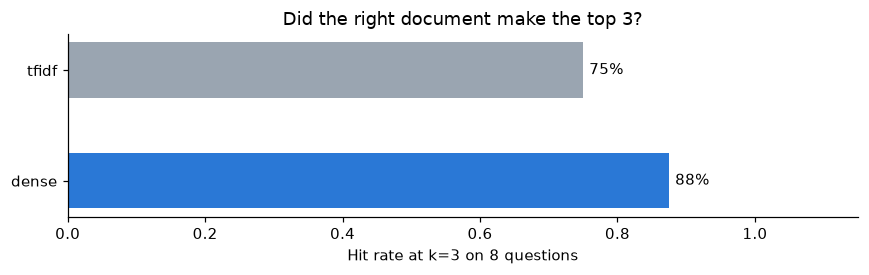

trap questions, best score under each method (lower is better; compare with the threshold of section 4):
  tfidf  {'What is the capital of Australia...': 0.0, 'Who won the 2022 football World ...': 0.085}
  dense  {'What is the capital of Australia...': 0.11599999666213989, 'Who won the 2022 football World ...': 0.0949999988079071}


In [10]:
eval_set = [
    ("Which metric grades the irony project?", "M3 - Natural Language Processing/README.md"),
    ("How long must the Generative AI paper be?", "M4 - Generative AI/README.md"),
    ("What does read_file refuse to open?", "M5 - Harness Engineering/README.md"),
    ("Which licence does the repository use?", "README.md"),
    ("How do I report a security problem?", "SECURITY.md"),
    ("Which notebook sections does the session 2 deck pair with?", "presentations/README.md"),
    ("What random seed should every notebook use?", "CONTRIBUTING.md"),
    ("What is the required format of submission.csv for the irony project?", "M3 - Natural Language Processing/README.md"),
]
traps = ["What is the capital of Australia?", "Who won the 2022 football World Cup?"]


def evaluate_retrieval(method: str, k_values=(1, 3, 5), frame: pd.DataFrame | None = None) -> pd.DataFrame:
    rows = []
    for k in k_values:
        hits, rr = 0, 0.0
        for q, expected in eval_set:
            sources = retrieve(q, k=k, method=method)["source"].tolist()
            if expected in sources:
                hits += 1
                rr += 1 / (sources.index(expected) + 1)
        rows.append({"method": method, "k": k, "hit rate": hits / len(eval_set), "MRR": rr / len(eval_set)})
    return pd.DataFrame(rows)


methods = ["tfidf"] + (["dense"] if HAVE_DENSE else [])
results = pd.concat([evaluate_retrieval(m) for m in methods], ignore_index=True)
display(results.pivot(index="k", columns="method", values=["hit rate", "MRR"]).round(2))

fig, ax = plt.subplots(figsize=(8, 2.6))
at3 = results[results["k"] == 3].set_index("method")["hit rate"]
bars = ax.barh(at3.index, at3.values, color=[GREY if m == "tfidf" else BLUE for m in at3.index], height=0.5)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in at3.values], padding=4)
ax.set_xlim(0, 1.15)
ax.invert_yaxis()
ax.set_xlabel(f"Hit rate at k=3 on {len(eval_set)} questions")
ax.set_title("Did the right document make the top 3?")
plt.tight_layout()
plt.show()

print("trap questions, best score under each method (lower is better; compare with the threshold of section 4):")
for m in methods:
    print(f"  {m:<6}", {q[:32] + "...": float(retrieve(q, k=1, method=m).score.iloc[0]) for q in traps})

**How to read it:** one bar per embedding method; the length is the share of test questions whose expected document appears in the top three. The table above adds k=1 and k=5 and the mean reciprocal rank. Eight questions is a smoke test, not a benchmark: in a real project you want fifty or more, written by people who did not build the system, and you rerun them every time you change the chunker, the embedding model or k.

## 8. Design choices and failure modes

Every box of the pipeline is a decision. The table lists the ones that move results most, in roughly the order you should try them.

| Choice | Typical options | What it changes |
|---|---|---|
| Chunk size and overlap | 100 to 500 words; 10 to 20 percent overlap; or structure-aware (by heading, by section) | Recall of facts versus noise in the prompt; cost per call |
| Embedding | TF-IDF or BM25; a small dense model; a large one; **hybrid** of both with a reranker | Recall on paraphrases versus exactness on names, codes and numbers |
| k and threshold | 3 to 10 passages; a minimum score to answer at all | Missing answers versus noise; whether "not in the documents" is ever said |
| Metadata and filters | Store the source, date, section, access rights with each chunk | Fresh answers, access control, citations users can click |
| Query handling | Rewrite vague questions; split compound ones; expand with synonyms | Retrieval quality on real user questions, which are worse than test questions |
| Prompt instructions | Cite, quote exactly, decline when unsupported | Faithfulness; whether the model ignores its context |
| Index refresh | Re-embed on every document change | Stale answers, the most common RAG complaint in production |

The failure modes follow from the same boxes:

1. **The wrong passage is retrieved.** The answer is confidently wrong, with a citation. Fix the retriever, not the prompt: chunking, hybrid search, reranking, a threshold.
2. **The right passage is retrieved and the model ignores it.** Fix the instructions, lower k, put the passages closer to the question, or change the model; measure faithfulness.
3. **The answer needs several passages combined** (multi-hop questions). Retrieve more, iterate (retrieve, draft, retrieve again), or let an agent decide when to search, which is where RAG meets the harness engineering of Module 5.
4. **Prompt injection through documents.** A retrieved passage can contain text written to steer the model ("ignore your instructions and..."). The system puts untrusted text into the prompt by design, so retrieved text must be treated as data, never as instructions, and tools reachable from the answer must be guarded by code. Module 5's hooks and permissions are exactly that guard.

When is RAG the wrong tool? When the knowledge is a style or a skill rather than facts (fine-tune), when the whole corpus is a few pages and never changes (put it in the prompt), and when the question needs reasoning over the entire corpus rather than a few passages (aggregate first, with code).

## 9. Key takeaways

- A language model takes a closed-book exam. RAG makes it open book: retrieve the few passages that matter, put only those in the prompt, make the model cite them.
- Five steps: chunk, embed, retrieve, augment, generate. Indexing is offline; querying is per question. The model sees only the prompt.
- An embedding is a vector; cosine similarity says how aligned two vectors are. Keyword embeddings are exact on names and numbers; dense embeddings understand paraphrase; production systems use both.
- Retrieval is tested with hit rate and MRR on questions with known sources, plus trap questions. Generation is tested on faithfulness and relevance. Test both, every time something changes.
- The quality of the answer is capped by the quality of the retrieved passages, and retrieved text is untrusted input. The engineering around the model decides whether RAG works.

## 10. Exercises

Try these before looking at the solutions.

**Exercise 1 - Chunk size.** Rebuild the chunks with `target_words` of 40 and of 250, rebuild the TF-IDF index for each, and recompute hit rate at k=3 on the eval set. Which size wins here, and why might the answer differ on a corpus of long reports?

**Exercise 2 - A new document.** Add a short document of your own to `documents` (for example a fictional course rule: "Late work loses one point per day, up to three days"), rebuild the chunks and the index, and ask a question that only your document can answer. Does it come top? Does the prompt cite it?

**Exercise 3 - Honest declines.** Write two more trap questions of your own, one far from the corpus and one close to it (about a course detail that is not written anywhere). Check the best scores against the threshold. Which one is dangerous, and what would you change?

## 11. Solutions

**Solution 1 - Chunk size.** Small chunks make precise hits but lose context and multiply the number of passages; large chunks keep context but blur the embedding and cost more per call. On short README files, medium chunks tend to win; on long reports the best size is usually larger and structure-aware (by section). The only way to know is to measure, which is what the cell does.

In [11]:
def hit_rate_at_3_for(target_words: int, method: str = "tfidf") -> float:
    frame = build_chunks(target_words)
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=1, sublinear_tf=True, stop_words="english")
    matrix = vec.fit_transform(frame["text"])
    hits = 0
    for q, expected in eval_set:
        scores = (matrix @ vec.transform([q]).T).toarray().ravel()
        if expected in frame.iloc[np.argsort(scores)[::-1][:3]]["source"].tolist():
            hits += 1
    return hits / len(eval_set), len(frame)


for size in (40, 100, 250):
    rate, n = hit_rate_at_3_for(size)
    print(f"target {size:>3} words -> {n:>3} chunks, TF-IDF hit rate at 3: {rate:.0%}")

target  40 words -> 130 chunks, TF-IDF hit rate at 3: 75%
target 100 words ->  81 chunks, TF-IDF hit rate at 3: 75%
target 250 words ->  35 chunks, TF-IDF hit rate at 3: 75%


**Solution 2 - A new document.** Adding a document means re-indexing: chunks, embeddings and the matrix are rebuilt. The question is phrased with different words from the rule on purpose, so TF-IDF has to rely on the overlapping terms while a dense model matches the meaning.

In [12]:
documents["course-rules.md"] = ("# Course rules\n\nLate work loses one point per day, up to three days. "
                                "After three days the project is graded as not handed in.")
chunks = build_chunks(target_words=100)
chunk_tfidf = tfidf.fit_transform(chunks["text"])
if HAVE_DENSE:
    chunk_dense = embed_dense(chunks["text"].tolist())

new_q = "What happens if I hand in my project two days after the deadline?"
hits = retrieve(new_q, k=3, method=DEFAULT_METHOD)
print(f"Q: {new_q}")
show(hits)
print("\ntop source is the new document:", hits.source.iloc[0] == "course-rules.md")

Q: What happens if I hand in my project two days after the deadline?
  0.556  course-rules.md [chunk 0]  # Course rules Late work loses one point per day, up to three days. After three days the project is graded as not handed in....
  0.290  M4 - Generative AI/README.md [chunk 11]  What the points do not cover is handled as follows: a paper more than 10 percent over or under length loses 5 points; a missing appendix scores 0 on that criter...
  0.241  M4 - Generative AI/README.md [chunk 15]  ## Checklist before you send - The five headings appear in the given order; the word count (title, references and appendix excluded) is between 1,350 and 1,650....

top source is the new document: True


**Solution 3 - Honest declines.** The far question scores low under any embedding and the threshold catches it. The near question is the dangerous one: it is about the course, so it lands on course passages with respectable scores, and a model under weak instructions will answer from the nearest passage. The defence is the instruction to decline when unsupported, a tighter threshold, and an evaluation set that contains exactly this kind of question.

In [13]:
near_trap = "How many students are enrolled in this course?"
far_trap = "What is the boiling point of mercury?"
for q in (far_trap, near_trap):
    best = retrieve(q, k=1, method=DEFAULT_METHOD)
    verdict = "below threshold: decline" if best.score.iloc[0] < THRESHOLD else "above threshold: passages reach the model"
    print(f"{best.score.iloc[0]:.3f}  {verdict:<42}  {q}  -> nearest: {best.source.iloc[0]}")

0.085  below threshold: decline                    What is the boiling point of mercury?  -> nearest: M3 - Natural Language Processing/README.md
0.359  above threshold: passages reach the model   How many students are enrolled in this course?  -> nearest: M5 - Harness Engineering/README.md


## References

- Lewis, P., et al. (2020). Retrieval-augmented generation for knowledge-intensive NLP tasks. *Advances in Neural Information Processing Systems* 33. arXiv:2005.11401.
- Karpukhin, V., et al. (2020). Dense passage retrieval for open-domain question answering. *Proceedings of EMNLP 2020*. arXiv:2004.04906.
- Reimers, N., & Gurevych, I. (2019). Sentence-BERT: Sentence embeddings using Siamese BERT-networks. *Proceedings of EMNLP-IJCNLP 2019*. arXiv:1908.10084.
- Robertson, S., & Zaragoza, H. (2009). The probabilistic relevance framework: BM25 and beyond. *Foundations and Trends in Information Retrieval*, 3(4), 333–389.
- Liu, N. F., et al. (2023). Lost in the middle: How language models use long contexts. arXiv:2307.03172.
- Gao, Y., et al. (2023). Retrieval-augmented generation for large language models: A survey. arXiv:2312.10997.
- Es, S., James, J., Espinosa-Anke, L., & Schockaert, S. (2023). RAGAS: Automated evaluation of retrieval augmented generation. arXiv:2309.15217.
- The embedding model used when available: `sentence-transformers/all-MiniLM-L6-v2` on the Hugging Face Hub.